<h1><center> Full Data Cleaning, Visualisation, EDA on 'Penguins' Dataset

In [32]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import chi2_contingency


## 1)- Chargement des données

In [33]:
data = sns.load_dataset('penguins')
data

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female
...,...,...,...,...,...,...,...
339,Gentoo,Biscoe,NaN,NaN,NaN,NaN,NaN
340,Gentoo,Biscoe,46.8,14.3,215.0,4850.0,Female
341,Gentoo,Biscoe,50.4,15.7,222.0,5750.0,Male
342,Gentoo,Biscoe,45.2,14.8,212.0,5200.0,Female


## 2)- La taille des données

In [34]:
data.shape

(344, 7)

## 3)- Apperçu général sur les données

In [35]:
data.head()

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female


## 4)- Les types des données

In [36]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    object 
 1   island             344 non-null    object 
 2   bill_length_mm     342 non-null    float64
 3   bill_depth_mm      342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                333 non-null    object 
dtypes: float64(4), object(3)
memory usage: 18.9+ KB


## 5)- Statistiques descriptives générales

In [37]:
data.describe()

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
count,342.000000,342.000000,342.000000,342.000000
mean,43.921930,17.151170,200.915205,4201.754386
std,5.459584,1.974793,14.061714,801.954536
min,32.100000,13.100000,172.000000,2700.000000
25%,39.225000,15.600000,190.000000,3550.000000
50%,44.450000,17.300000,197.000000,4050.000000
75%,48.500000,18.700000,213.000000,4750.000000
max,59.600000,21.500000,231.000000,6300.000000


## 6)- Les valeurs manquantes

<h3> a)- Détection des valeurs nulles

In [38]:
data.isnull().sum()

species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
dtype: int64

<h3> b)- Traiter les valeurs nulles

In [39]:
# on va choisr de remplacer les valeurs numériques nulles par la moyenne

data['bill_length_mm'].fillna(data['bill_length_mm'].mean(), inplace=True)
data['bill_depth_mm'].fillna(data['bill_depth_mm'].mean(), inplace=True)
data['flipper_length_mm'].fillna(data['flipper_length_mm'].mean(), inplace=True)
data['body_mass_g'].fillna(data['body_mass_g'].mean(), inplace=True)

data.isnull().sum()

species               0
island                0
bill_length_mm        0
bill_depth_mm         0
flipper_length_mm     0
body_mass_g           0
sex                  11
dtype: int64

In [40]:
# et on va remplacer la variable 'sex' par le mode

data['sex'].fillna(data['sex'].mode()[0], inplace=True)

data.isnull().sum()

species              0
island               0
bill_length_mm       0
bill_depth_mm        0
flipper_length_mm    0
body_mass_g          0
sex                  0
dtype: int64

## 7)- Les valeurs dupliquées

In [42]:
data.duplicated().sum() # on n'a pas de valeurs dupliquées !

0

## 8)- Standariser les formats

<h4> a)- la colonne 'species'

In [43]:
data['species'].unique()

array(['Adelie', 'Chinstrap', 'Gentoo'], dtype=object)

<h4> b)- la colonne 'island'

In [44]:
data['island'].unique()

array(['Torgersen', 'Biscoe', 'Dream'], dtype=object)

<h4> c)- la colonne 'bill_length_mm'

In [46]:
data["bill_length_mm"].min(), data['bill_length_mm'].max()

(32.1, 59.6)

<h4> d)- la colonne 'bill_depth_mm'

In [47]:
data["bill_depth_mm"].min(), data['bill_depth_mm'].max()

(13.1, 21.5)

<h4> e)- la colonne 'flipper_length_mm '

In [48]:
data["flipper_length_mm"].min(), data['flipper_length_mm'].max()

(172.0, 231.0)

<h4> f)- la colonne 'body_mass_g'

In [49]:
data["body_mass_g"].min(), data['body_mass_g'].max()

(2700.0, 6300.0)

<h4> g)- la colonne 'sex'

In [50]:
data['sex'].unique()

array(['Male', 'Female'], dtype=object)

In [51]:
# Rien à standariser !!!

## 9)- Visualisation

In [52]:
data['species'].value_counts()

Adelie       152
Gentoo       124
Chinstrap     68
Name: species, dtype: int64

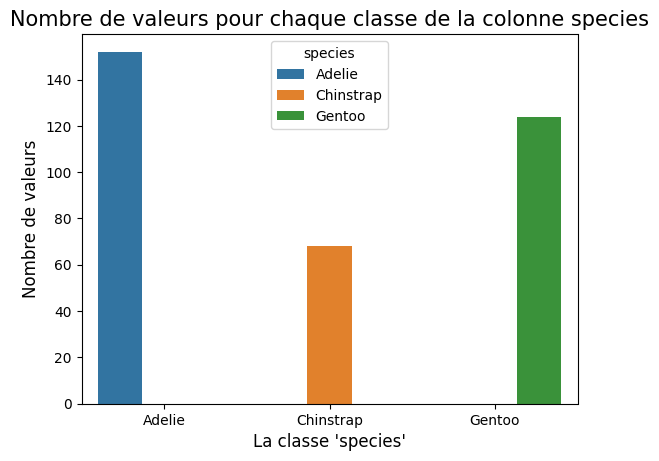

In [77]:
plt.title("Nombre de valeurs pour chaque classe de la colonne species", fontsize= 15)
sns.countplot(data, x= 'species', hue='species')
plt.xlabel('La classe \'species\'', fontsize= 12)
plt.ylabel("Nombre de valeurs", fontsize= 12)
plt.show()

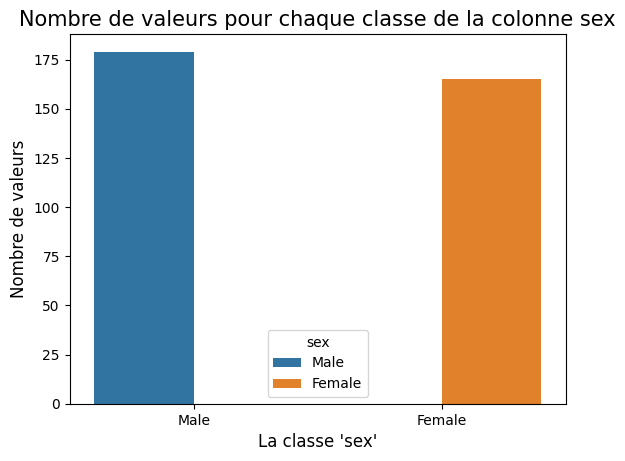

In [76]:
plt.title("Nombre de valeurs pour chaque classe de la colonne sex", fontsize= 15)
sns.countplot(data, x= 'sex', hue='sex')
plt.xlabel('La classe \'sex\'', fontsize= 12)
plt.ylabel("Nombre de valeurs", fontsize= 12)
plt.show()

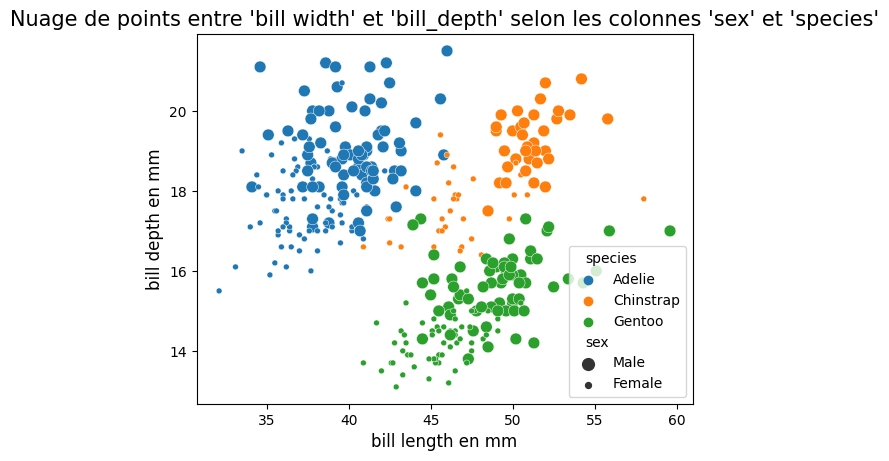

In [75]:
plt.title("Nuage de points entre 'bill width' et 'bill_depth' selon les colonnes 'sex' et 'species'", fontsize= 15)
sns.scatterplot(data=data, x='bill_length_mm', y='bill_depth_mm', hue='species', size='sex')

plt.xlabel('bill length en mm', fontsize=12)
plt.ylabel('bill depth en mm', fontsize=12)
plt.show()


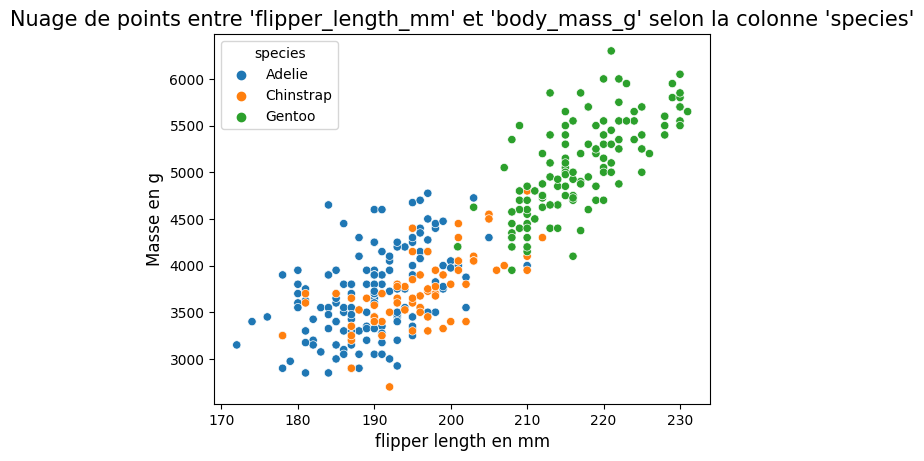

In [79]:
plt.title("Nuage de points entre 'flipper_length_mm' et 'body_mass_g' selon la colonne 'species'", fontsize= 15)
sns.scatterplot(data=data, x='flipper_length_mm', y='body_mass_g', hue='species')

plt.xlabel('flipper length en mm', fontsize=12)
plt.ylabel('Masse en g', fontsize=12)
plt.show()


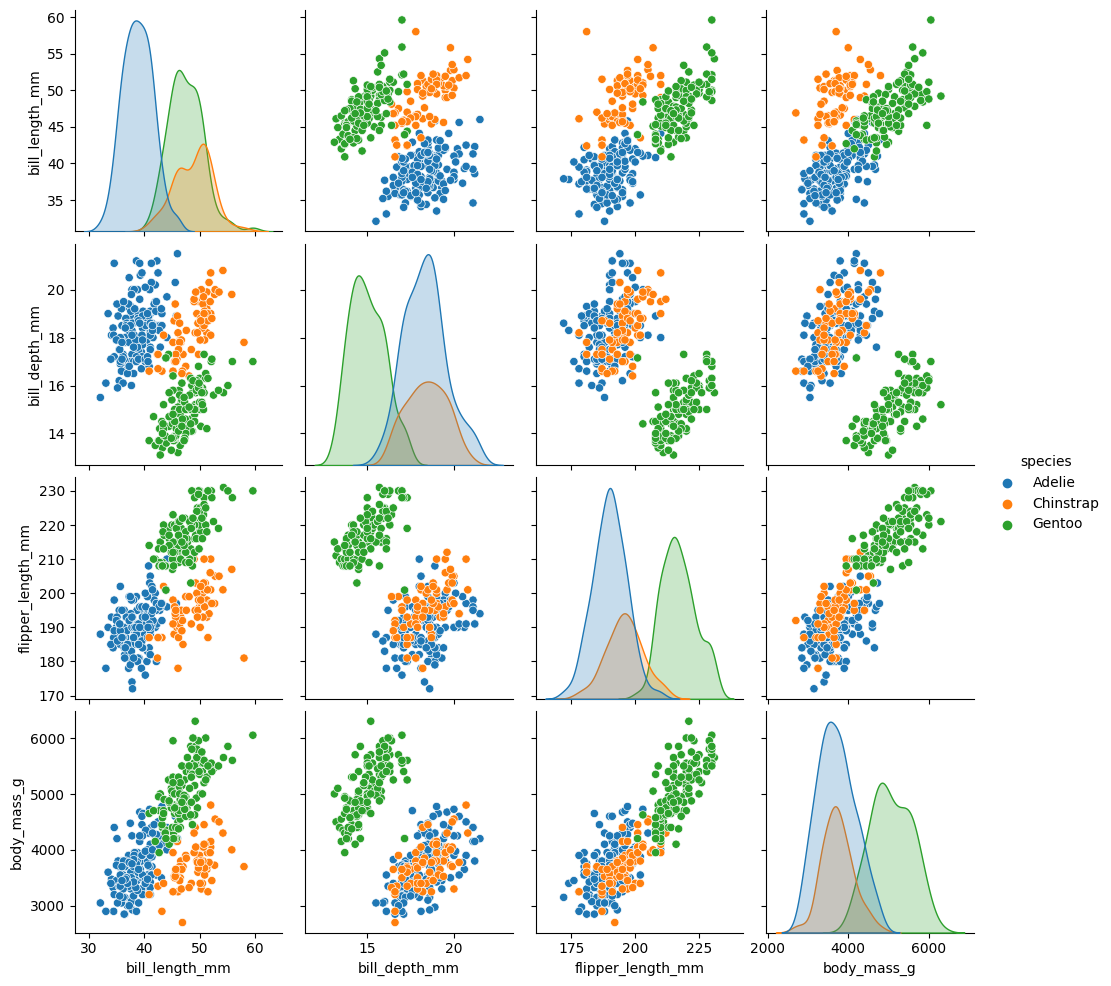

In [81]:
# Pairplot

sns.pairplot(data=data, hue='species')
plt.show()

In [83]:
# HeatMap

corr_mat = data.corr(numeric_only=True)
corr_mat

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
bill_length_mm,1.000000,-0.235053,0.656181,0.595110
bill_depth_mm,-0.235053,1.000000,-0.583851,-0.471916
flipper_length_mm,0.656181,-0.583851,1.000000,0.871202
body_mass_g,0.595110,-0.471916,0.871202,1.000000


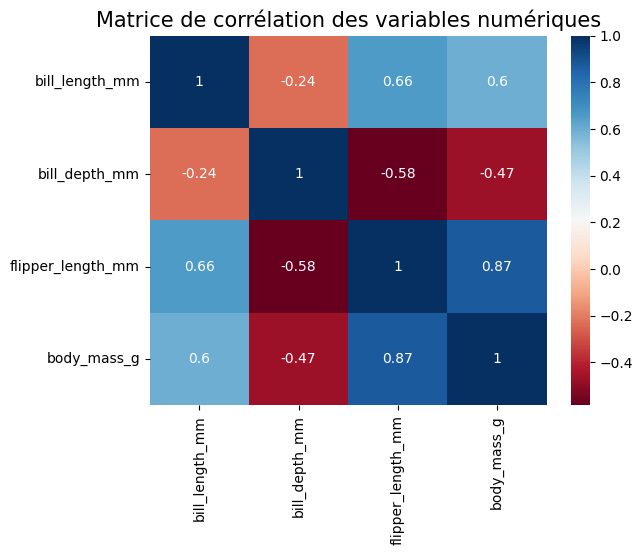

In [90]:
plt.title("Matrice de corrélation des variables numériques", fontsize=15)
sns.heatmap(corr_mat, annot=True,cmap='RdBu')
plt.show()

- Si bill_depth_mm augmente alors bill_length_mm diminue (-0.24)
- Si flipper_length_mm augmente alors bill_length_mm augmente (0.66)
- Si flipper_length_mm augmente alors bill_depth_mm diminue (-0.58)
- Si body_mass_g augmente alors bill_length_mm augmente (0.6)
- Si bill_depth_mm augmente alors body_mass diminue (-0.47)
- Si flipper_le,gth_mm augmente alors body_mass_g augmente (0.87)

## 10)- Test de Chi2

In [103]:
# entre species et island

contingency = pd.crosstab(data['species'], data['island'])
chi2, pvalue, ddl, Eij = chi2_contingency(contingency)

print("la table de contingence est : \n", contingency)
print("--------"*5)
print("Les valeurs de Eij sont : \n", Eij, "\n")
print("--------"*5)
print("La valeur de p_value est : ", pvalue)
print("Le degré de liberté est : ", ddl)
print("Les valeurs de Chi2 sont : ", chi2)
print("--------"*5)


alpha = 0.05 # choix personnel 
if pvalue < alpha:
    print("On a une relation significative entre species et island")
else:
    print("On n'a pas de relation entre species et island")

la table de contingence est : 
 island     Biscoe  Dream  Torgersen
species                            
Adelie         44     56         52
Chinstrap       0     68          0
Gentoo        124      0          0
----------------------------------------
Les valeurs de Eij sont : 
 [[74.23255814 54.79069767 22.97674419]
 [33.20930233 24.51162791 10.27906977]
 [60.55813953 44.69767442 18.74418605]] 

----------------------------------------
La valeur de p_value est :  1.354573829719252e-63
Le degré de liberté est :  4
Les valeurs de Chi2 sont :  299.55032743148195
----------------------------------------
On a une relation significative entre species et island


In [104]:
# entre species et sex

contingency = pd.crosstab(data['species'], data['sex'])
chi2, pvalue, ddl, Eij = chi2_contingency(contingency)

print("la table de contingence est : \n", contingency)
print("--------"*5)
print("Les valeurs de Eij sont : \n", Eij, "\n")
print("--------"*5)
print("La valeur de p_value est : ", pvalue)
print("Le degré de liberté est : ", ddl)
print("Les valeurs de Chi2 sont : ", chi2)
print("--------"*5)


alpha = 0.05 # choix personnel 
if pvalue < alpha:
    print("On a une relation significative entre species et sex")
else:
    print("On n'a pas de relation entre species et sex")

la table de contingence est : 
 sex        Female  Male
species                
Adelie         73    79
Chinstrap      34    34
Gentoo         58    66
----------------------------------------
Les valeurs de Eij sont : 
 [[72.90697674 79.09302326]
 [32.61627907 35.38372093]
 [59.47674419 64.52325581]] 

----------------------------------------
La valeur de p_value est :  0.9123297194631974
Le degré de liberté est :  2
Les valeurs de Chi2 sont :  0.18350763949307053
----------------------------------------
On n'a pas de relation entre species et sex


<h1><center> The END